# 03: Survival analysis: what makes a case slow?

Week 3. Kaplan-Meier curves by case category and district, log-rank tests, and a **stratified Cox
model** that ranks districts after adjusting for case mix. The raw district medians in `02_eda`
are confounded: a district with many bail applications looks fast even if every court in it is
slow.

Analysis choices (see `docs/DECISIONS.md`):
- **D-011:** observation ends on **2020-03-15**. Cases still open then, or decided later, are
  censored at that date, because the COVID lockdown collapsed decision rates from late March 2020.
- Rows with `bad_dates` are dropped (0.5%, all negative durations).
- Transfers and Lok Adalat referrals still count as decisions (D-005).

In [1]:
import matplotlib.pyplot as plt
import matplotlib.ticker as mt
import numpy as np
import pandas as pd
from lifelines import CoxPHFitter, KaplanMeierFitter
from lifelines.statistics import logrank_test, multivariate_logrank_test, proportional_hazard_test

from court_delay.config import ADMIN_CENSOR_DATE, PROCESSED, ROOT
from court_delay.categories import CRIMINAL
from court_delay.survival import aggregate, censor_at, is_court_system

FIG = ROOT / "reports" / "figures"
FIG.mkdir(parents=True, exist_ok=True)

# Reference palette (dataviz skill), light mode. Validated: blue/orange pass all CVD checks.
SURFACE, INK, INK2, GRID = "#fcfcfb", "#0b0b0b", "#52514e", "#e6e5e1"
BLUE, ORANGE, MUTED = "#2a78d6", "#eb6834", "#a9a8a3"
GROUP = {1: ("Criminal", BLUE), 0: ("Civil", ORANGE)}
plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "figure.dpi": 110, "savefig.dpi": 160, "font.size": 10,
    "text.color": INK, "axes.labelcolor": INK2, "xtick.color": INK2, "ytick.color": INK2,
    "axes.edgecolor": GRID, "axes.linewidth": 0.8, "axes.grid": True, "grid.color": GRID,
    "grid.linewidth": 0.6, "axes.spines.top": False, "axes.spines.right": False,
    "axes.titlesize": 12, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "axes.titlepad": 12, "lines.linewidth": 2, "legend.frameon": False,
})

def finish(fig, name, source=True):
    if source:
        fig.text(0.01, -0.03, "Source: Development Data Lab e-Courts data, Maharashtra cases filed 2010–2018. "
                 "Kaplan-Meier on right-censored durations.", fontsize=7.5, color=INK2)
    fig.savefig(FIG / f"{name}.png", bbox_inches="tight")
    plt.show()


def kmw(agg):
    """Kaplan-Meier on an aggregated (duration, event, n) frame."""
    return KaplanMeierFitter().fit(agg["duration_days"], agg["event"], weights=agg["n"])

raw = pd.read_parquet(PROCESSED / "cases_maharashtra.parquet", columns=[
    "year", "district_name", "case_category", "is_criminal", "filing_date", "date_last_list",
    "event", "duration_days", "bad_dates"])
raw = raw[~raw["bad_dates"]].drop(columns="bad_dates").reset_index(drop=True)
df = censor_at(raw, ADMIN_CENSOR_DATE)
df["case_category"] = df["case_category"].astype("category")
df["court_system"] = is_court_system(df["district_name"])
print(f"{len(df):,} cases, {1 - df.event.mean():.1%} censored at {ADMIN_CENSOR_DATE}")

10,007,058 cases, 27.6% censored at 2020-03-15


## 1. Two data checks before modelling

**COVID cutoff.** How much does ending observation on 2020-03-15 instead of 2020-09-10 change things?

In [2]:
cmp = pd.DataFrame({
    "censored share": [1 - raw.event.mean(), 1 - df.event.mean()],
    "KM median (days)": [kmw(aggregate(raw)).median_survival_time_, kmw(aggregate(df)).median_survival_time_],
}, index=["to 2020-09-10", "to 2020-03-15 (D-011)"])
moved = ((raw.event == 1) & (df.event == 0)).sum()
print(f"decisions between 2020-03-15 and 2020-09-10: {moved:,} ({moved / raw.event.sum():.2%} of all decisions)")
cmp.round(3)

decisions between 2020-03-15 and 2020-09-10: 2,142 (0.03% of all decisions)


,censored share,KM median (days)
to 2020-09-10,0.276,583.0
to 2020-03-15 (D-011),0.276,579.0


**Long-pending cases.** About 111k cases were still pending after 9+ years and almost none of them
were decided. Are they stale records (abandoned but never closed), or are courts still hearing them?
The test: how long before the cutoff was their last hearing?

In [3]:
pend = raw[raw.event == 0]
gap = (pd.Timestamp("2020-09-10") - pend["date_last_list"]).dt.days
old = pend["duration_days"] > 9 * 365.25
stale = pd.DataFrame({
    "cases": [len(pend), old.sum()],
    "no hearing recorded": [gap.isna().mean(), gap[old].isna().mean()],
    "last hearing > 2 years before cutoff": [(gap > 730).mean(), (gap[old] > 730).mean()],
    "median days since last hearing": [gap.median(), gap[old].median()],
}, index=["all pending", "pending 9+ years"])
stale.round(3)

,cases,no hearing recorded,last hearing > 2 years before cutoff,median days since last hearing
all pending,2763448,0.000,0.020,600.0
pending 9+ years,110976,0.004,0.036,589.0


## 2. Kaplan-Meier by case category

Each panel shows one category against the statewide curve (grey). Blue = criminal, orange = civil.
Panels are sorted from fastest to slowest median.

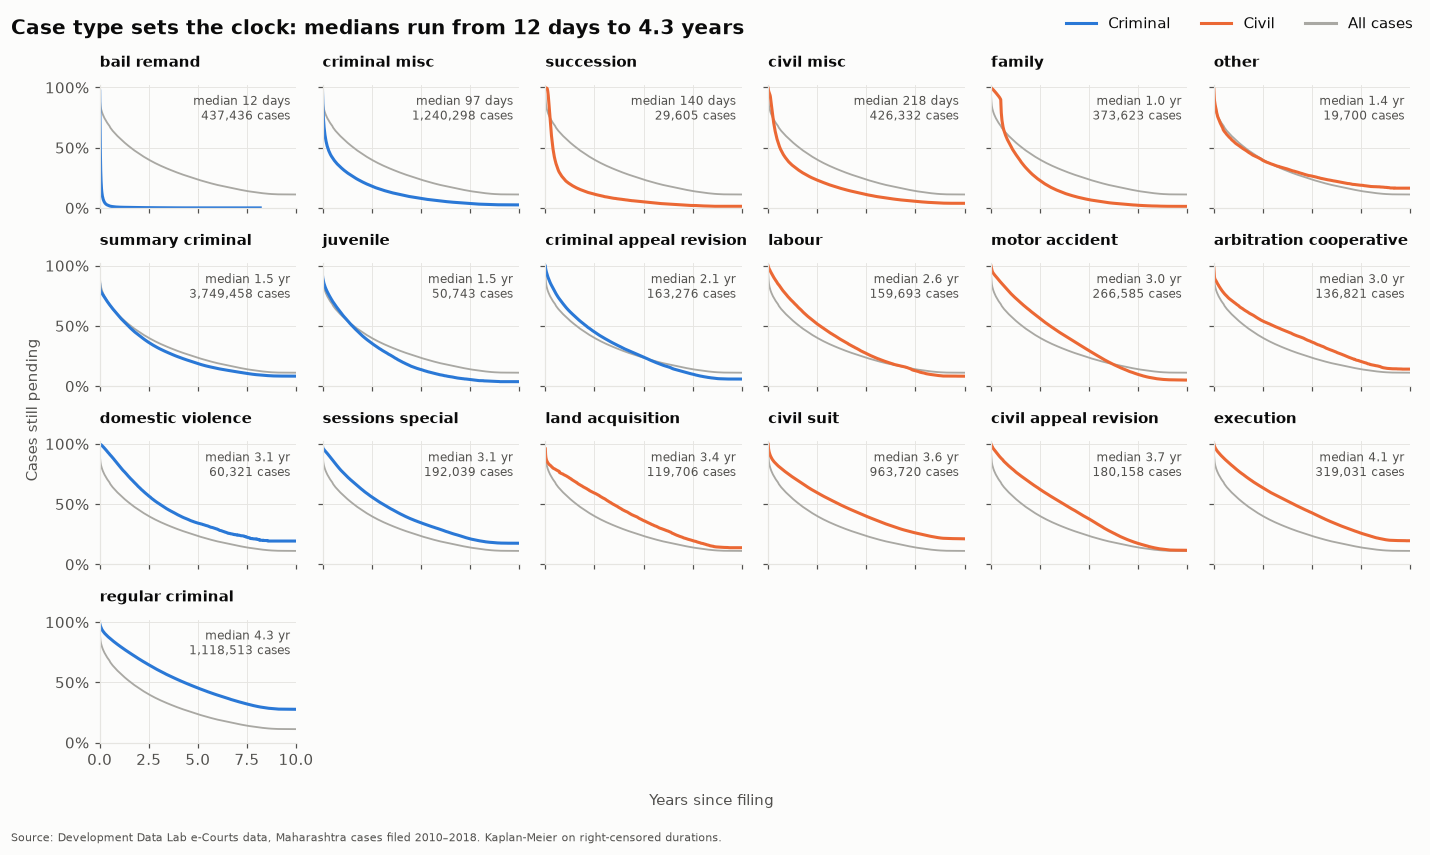

,KM median (days),cases
bail_remand,12.0,437436
criminal_misc,97.0,1240298
succession,140.0,29605
civil_misc,218.0,426332
family,383.0,373623
other,518.0,19700
summary_criminal,532.0,3749458
juvenile,555.0,50743
criminal_appeal_revision,760.0,163276
labour,962.0,159693


In [4]:
agg_cat = aggregate(df, "case_category")
state_km = kmw(aggregate(df))
km_cat = {c: kmw(g) for c, g in agg_cat.groupby("case_category", observed=True)}
med = pd.Series({c: k.median_survival_time_ for c, k in km_cat.items()}).sort_values()
n_cat = agg_cat.groupby("case_category", observed=True)["n"].sum()

def curve(k, years=10):
    s = k.survival_function_.iloc[:, 0]
    s = s[s.index <= years * 365.25]
    return s.index / 365.25, s.values

cats = list(med.index)
ncol = 6
fig, axes = plt.subplots(int(np.ceil(len(cats) / ncol)), ncol, figsize=(13, 7.4), sharex=True, sharey=True)
sx, sy = curve(state_km)
for ax, c in zip(axes.flat, cats):
    color = BLUE if c in CRIMINAL else ORANGE
    ax.plot(sx, sy, color=MUTED, lw=1.2)
    ax.plot(*curve(km_cat[c]), color=color)
    m = med[c]
    label = (f"{m:.0f} days" if m < 365 else f"{m / 365.25:.1f} yr") if np.isfinite(m) else "> 10 yr"
    ax.set_title(c.replace("_", " "), fontsize=9.5)
    ax.text(.97, .93, f"median {label}\n{n_cat[c]:,} cases", transform=ax.transAxes,
            ha="right", va="top", fontsize=8, color=INK2)
    ax.set_xlim(0, 10); ax.set_ylim(0, 1.02)
    ax.yaxis.set_major_formatter(mt.PercentFormatter(1, decimals=0))
for ax in axes.flat[len(cats):]:
    ax.set_visible(False)
fig.supxlabel("Years since filing", fontsize=10, color=INK2)
fig.supylabel("Cases still pending", fontsize=10, color=INK2)
fig.legend(handles=[plt.Line2D([], [], color=c) for c in (BLUE, ORANGE, MUTED)],
           labels=["Criminal", "Civil", "All cases"], loc="upper right", ncol=3, bbox_to_anchor=(1, 1.0))
fig.suptitle(f"Case type sets the clock: medians run from {med.iloc[0]:.0f} days to "
             f"{med[np.isfinite(med)].iloc[-1] / 365.25:.1f} years", x=0.01, ha="left",
             fontsize=13, fontweight="bold")
fig.tight_layout()
finish(fig, "07_km_by_category")
med.rename("KM median (days)").to_frame().join(n_cat.rename("cases"))

## 3. Log-rank tests

The log-rank test asks whether groups share one survival curve. With 10M cases almost any
difference is "significant", so the p-values matter less than the size of the gap. The last row
is the check: the two districts with the closest medians.

In [5]:
def lr_multi(by):
    a = aggregate(df, by)
    r = multivariate_logrank_test(a["duration_days"], a[by], a["event"], weights=a["n"])
    return r.test_statistic, r.p_value, a[by].nunique()

agg_dist = aggregate(df, "district_name")
km_dist = {d: kmw(g) for d, g in agg_dist.groupby("district_name")}
dmed = pd.Series({d: k.median_survival_time_ for d, k in km_dist.items()}).sort_values()
geo = dmed[~is_court_system(dmed.index.to_series()).values]
i = np.argmin(np.diff(geo.values))
d1, d2 = geo.index[i], geo.index[i + 1]
a1, a2 = agg_dist[agg_dist.district_name == d1], agg_dist[agg_dist.district_name == d2]
pair = logrank_test(a1.duration_days, a2.duration_days, a1.event, a2.event,
                    weights_A=a1.n, weights_B=a2.n)
ac = aggregate(df, "is_criminal")
civ, cri = ac[ac.is_criminal == 0], ac[ac.is_criminal == 1]
cc = logrank_test(civ.duration_days, cri.duration_days, civ.event, cri.event,
                  weights_A=civ.n, weights_B=cri.n)

rows = []
for name, by in [("18 case categories", "case_category"), ("40 districts / court systems", "district_name")]:
    stat, p, k = lr_multi(by)
    rows.append((name, k, stat, p))
rows.append(("civil vs criminal", 2, cc.test_statistic, cc.p_value))
rows.append((f"{d1} vs {d2} (medians {dmed[d1]:.0f} / {dmed[d2]:.0f} d)", 2, pair.test_statistic, pair.p_value))
pd.DataFrame(rows, columns=["comparison", "groups", "chi-square", "p-value"]).set_index("comparison")

,groups,chi-square,p-value
comparison,,,
18 case categories,19,3.275460e+06,0.000000
40 districts / court systems,40,2.254231e+05,0.000000
civil vs criminal,2,1.702093e+05,0.000000
Solapur vs Yavatmal (medians 567 / 567 d),2,1.974695e+01,0.000009


## 4. Cox model: district effects adjusted for case mix

Model on a random sample of 300,000 cases (the full 10M add nothing but runtime):

- **Stratified by case category.** Each category gets its own baseline hazard, so bail and
  warrant cases are never compared directly. This also handles the most obvious
  proportional-hazards violation.
- **District** uses deviation coding, so each hazard ratio compares a district with the
  *average district* (1.0 = average). A ratio above 1 means cases there are decided **faster**.
- **Filing year** is a linear term (centred on 2014).

In [6]:
SAMPLE = 300_000
s = df.sample(SAMPLE, random_state=42).reset_index(drop=True)
districts = sorted(df["district_name"].unique())

def design(frame, ref):
    X = pd.DataFrame({f"d:{d}": (frame.district_name == d).astype(float) - (frame.district_name == ref)
                      for d in districts if d != ref})
    X["filing_year"] = frame["year"].values - 2014.0
    X["duration_days"] = frame["duration_days"].values + 0.5   # same-day decisions get t > 0
    X["event"] = frame["event"].values
    X["category"] = frame["case_category"].astype(str).values
    return X

def fit(frame, ref, **kw):
    return CoxPHFitter().fit(design(frame, ref), "duration_days", "event", strata=["category"], **kw)

# Deviation coding leaves one district without its own row. Fit twice with different references
# and take each district's estimate from the fit where it is not the reference.
refA, refB = districts[0], districts[1]
fitA, fitB = fit(s, refA), fit(s, refB)
cols = ["coef", "coef lower 95%", "coef upper 95%", "p"]
eff = pd.concat([fitA.summary.loc[[c for c in fitA.summary.index if c.startswith("d:")], cols],
                 fitB.summary.loc[[f"d:{refA}"], cols]])
eff.index = eff.index.str[2:]
eff = np.exp(eff[cols[:3]]).set_axis(["hr", "lo", "hi"], axis=1).join(eff["p"])
eff["court_system"] = is_court_system(eff.index.to_series())
eff = eff.sort_values("hr")
print(f"filing year HR per year: {fitA.hazard_ratios_['filing_year']:.3f}, concordance {fitA.concordance_index_:.3f}")

filing year HR per year: 0.969, concordance 0.549


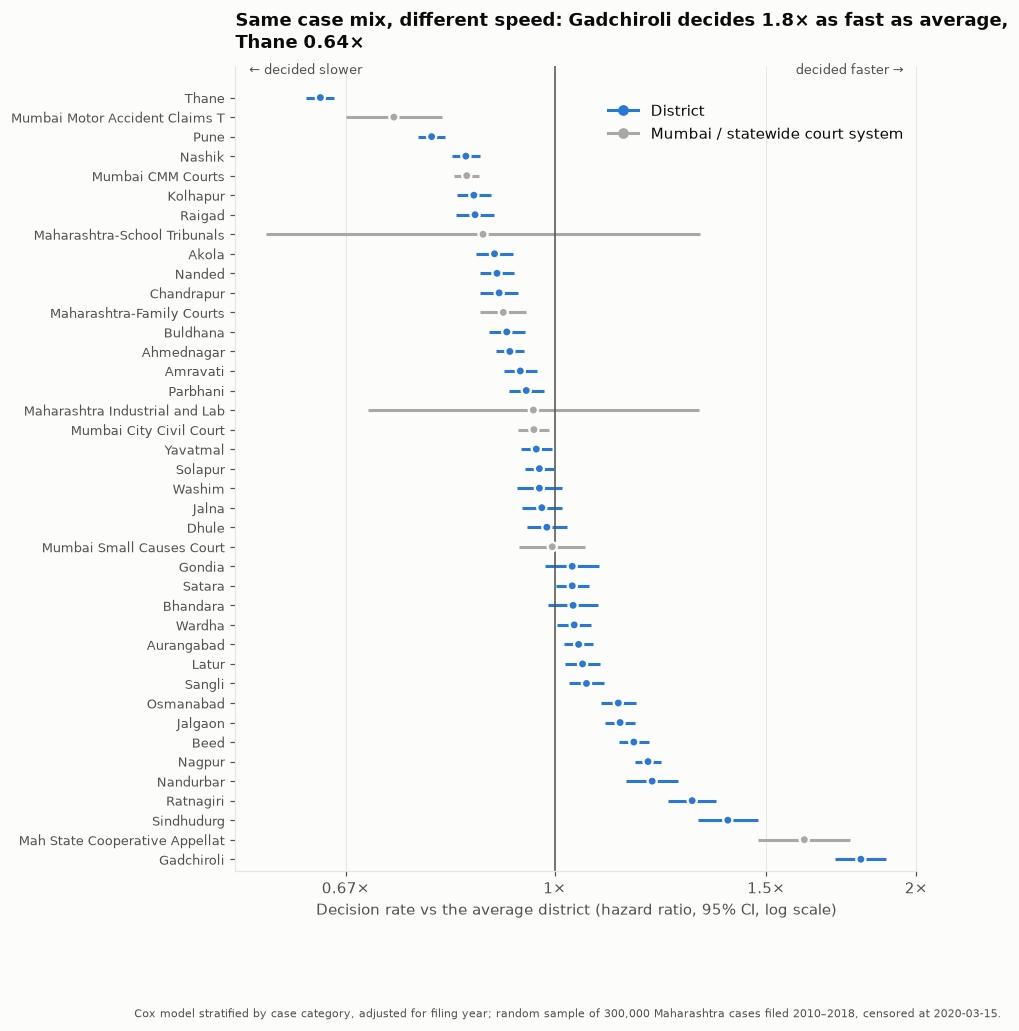

In [7]:
fig, ax = plt.subplots(figsize=(8, 9.5))
y = np.arange(len(eff))
colors = np.where(eff["court_system"], MUTED, BLUE)
ax.hlines(y, eff["lo"], eff["hi"], color=colors, lw=2)
ax.scatter(eff["hr"], y, color=colors, s=36, zorder=3, edgecolor=SURFACE, linewidth=1.5)
ax.axvline(1, color=INK2, lw=1)
ax.set_xscale("log")
ax.xaxis.set_major_locator(mt.FixedLocator([0.5, 0.67, 1, 1.5, 2]))
ax.xaxis.set_major_formatter(mt.FuncFormatter(lambda v, _: f"{v:g}×"))
ax.xaxis.set_minor_locator(mt.NullLocator())
ax.set_yticks(y, eff.index, fontsize=8.5)
ax.set_ylim(len(eff) - .4, -1.6)
ax.grid(axis="y", visible=False)
ax.text(0.98, -1.2, "decided faster →", ha="right", fontsize=8.5, color=INK2, transform=ax.get_yaxis_transform())
ax.text(0.02, -1.2, "← decided slower", ha="left", fontsize=8.5, color=INK2, transform=ax.get_yaxis_transform())
ax.legend(handles=[plt.Line2D([], [], color=c, marker="o", lw=2) for c in (BLUE, MUTED)],
          labels=["District", "Mumbai / statewide court system"], loc="upper right", bbox_to_anchor=(1, 0.97))
ax.set_xlabel("Decision rate vs the average district (hazard ratio, 95% CI, log scale)")
fast, slow = eff.index[-1], eff[~eff.court_system].index[0]
ax.set_title(f"Same case mix, different speed: {fast} decides {eff.hr.iloc[-1]:.1f}× as fast as average,\n"
             f"{slow} {eff.loc[slow, 'hr']:.2f}×")
fig.text(0.01, -0.03, f"Cox model stratified by case category, adjusted for filing year; random sample of "
         f"{SAMPLE:,} Maharashtra cases filed 2010–2018, censored at {ADMIN_CENSOR_DATE}.",
         fontsize=7.5, color=INK2)
finish(fig, "08_district_adjusted", source=False)

### Raw vs adjusted rankings

How much of the raw ranking in `02_eda` came from case mix? Each dot is a geographic district.
The raw median is on x, and the adjusted decision rate is on y.

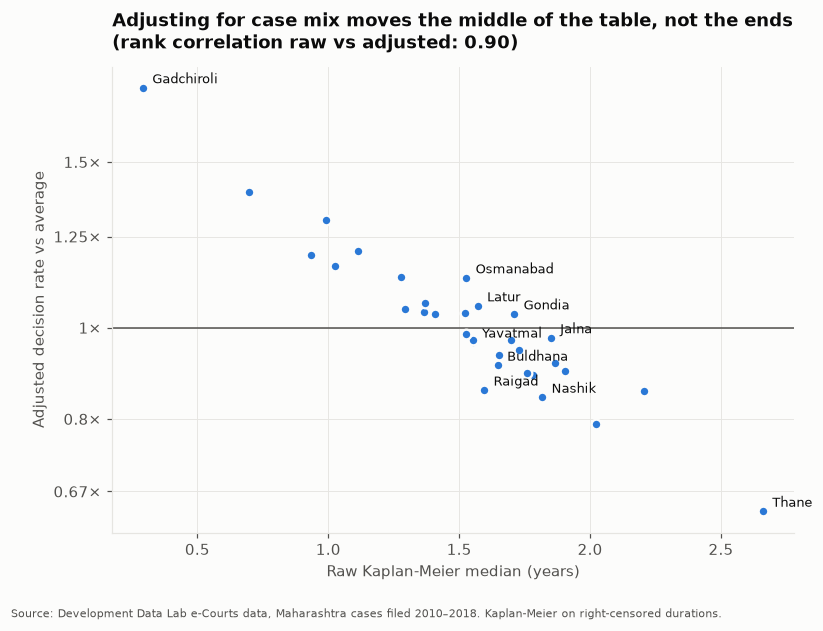

,raw_median,hr,criminal_share,raw_rank,adj_rank,moved
covariate,,,,,,
Raigad,583.0,0.86,0.61,18.0,28.0,-10.0
Buldhana,602.0,0.91,0.78,19.0,24.0,-5.0
Yavatmal,567.0,0.97,0.83,15.5,20.0,-4.5
Nashik,664.0,0.84,0.75,26.0,30.0,-4.0
Solapur,567.0,0.97,0.67,15.5,19.0,-3.5
Aurangabad,472.0,1.05,0.75,8.0,11.0,-3.0
Satara,514.0,1.03,0.68,11.0,14.0,-3.0
Dhule,557.0,0.99,0.71,13.0,16.0,-3.0
Wardha,499.0,1.04,0.86,9.0,12.0,-3.0


In [8]:
cmpd = eff[~eff.court_system].join(dmed.rename("raw_median"))
cmpd["criminal_share"] = df.groupby("district_name")["is_criminal"].mean()
cmpd["raw_rank"] = cmpd["raw_median"].rank()                  # 1 = fastest
cmpd["adj_rank"] = cmpd["hr"].rank(ascending=False)           # 1 = fastest
cmpd["moved"] = cmpd["raw_rank"] - cmpd["adj_rank"]
rho = cmpd[["raw_rank", "adj_rank"]].corr(method="spearman").iloc[0, 1]

fig, ax = plt.subplots(figsize=(8, 5.5))
ax.scatter(cmpd["raw_median"] / 365.25, cmpd["hr"], color=BLUE, s=40, edgecolor=SURFACE, linewidth=1.5, zorder=3)
ax.set_yscale("log")
ax.yaxis.set_major_locator(mt.FixedLocator([0.67, 0.8, 1, 1.25, 1.5, 2]))
ax.yaxis.set_major_formatter(mt.FuncFormatter(lambda v, _: f"{v:g}×"))
ax.yaxis.set_minor_locator(mt.NullLocator())
ax.axhline(1, color=INK2, lw=1)
label = pd.concat([cmpd.nlargest(4, "moved"), cmpd.nsmallest(4, "moved"),
                   cmpd.nlargest(1, "hr"), cmpd.nsmallest(1, "hr")])
for d, r in label[~label.index.duplicated()].iterrows():
    ax.annotate(d, (r.raw_median / 365.25, r.hr), xytext=(6, 3), textcoords="offset points", fontsize=8.5, color=INK)
ax.set_xlabel("Raw Kaplan-Meier median (years)")
ax.set_ylabel("Adjusted decision rate vs average")
ax.set_title(f"Adjusting for case mix moves the middle of the table, not the ends\n(rank correlation raw vs adjusted: {rho:.2f})")
finish(fig, "09_raw_vs_adjusted")
cmpd.sort_values("moved")[["raw_median", "hr", "criminal_share", "raw_rank", "adj_rank", "moved"]].round(2)

## 5. Checking the proportional-hazards assumption

The Cox model assumes each district's hazard ratio is the same at every case age. There are two
checks:

1. **Schoenfeld residual test** (`proportional_hazard_test`, rank time transform) on a 50k
   subsample. At this sample size it flags small violations, so read the size of each statistic,
   not only the p-value.
2. **Period split.** Fit the model once for the first year after filing (censored at day 365), and
   once for cases still pending at day 365 (left-truncated, entry at day 365). If the hazards are
   proportional, the two sets of district effects line up on the diagonal.

In [9]:
s50 = s.sample(50_000, random_state=1).reset_index(drop=True)
fit50 = fit(s50, refA)
ph = proportional_hazard_test(fit50, design(s50, refA), time_transform="rank").summary
ph.index = [i if isinstance(i, str) else i[0] for i in ph.index]
print(f"covariates with p < 0.01: {(ph.p < 0.01).sum()} of {len(ph)}")
ph.sort_values("test_statistic", ascending=False).head(10).round(4)

covariates with p < 0.01: 13 of 40


,test_statistic,p,-log2(p)
filing_year,59.0582,0.0000,45.8927
d:Satara,36.2668,0.0000,29.1143
d:Nanded,26.5798,0.0000,21.9150
d:Gadchiroli,25.8772,0.0000,21.3902
d:Latur,19.6050,0.0000,16.6803
d:Wardha,15.8439,0.0001,13.8274
d:Thane,15.1727,0.0001,13.3152
d:Sangli,13.5316,0.0002,12.0576
d:Sindhudurg,12.3356,0.0004,11.1358
d:Beed,12.1020,0.0005,10.9552


correlation of log HRs, year 1 vs later: all 0.04, geographic districts 0.47


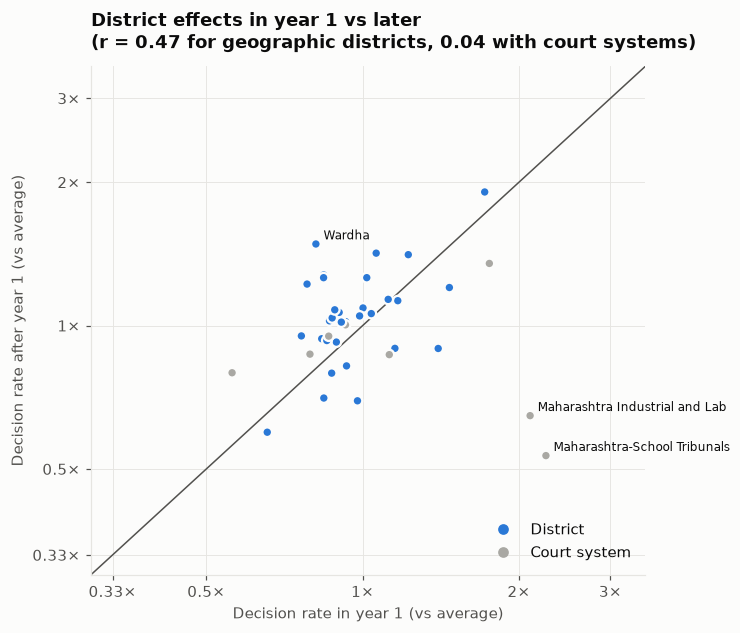

,year1_hr,after_hr,ratio
Maharashtra-School Tribunals,2.25,0.53,0.24
Maharashtra Industrial and Lab,2.10,0.65,0.31
Nagpur,1.40,0.90,0.64
Raigad,0.98,0.70,0.71
Mah State Cooperative Appellat,1.75,1.35,0.77
Mumbai Small Causes Court,1.13,0.87,0.77
Aurangabad,1.15,0.90,0.78
Sindhudurg,1.47,1.20,0.82
Pune,0.84,0.70,0.84
Nanded,0.93,0.82,0.88


In [10]:
early = s.copy()
over = early["duration_days"] > 365
early.loc[over, "duration_days"] = 365
early.loc[over, "event"] = 0
late = s[s["duration_days"] > 365].reset_index(drop=True)
Xl = design(late, refA)
Xl["entry"] = 365.5
fit_early = fit(early, refA)
fit_late = CoxPHFitter().fit(Xl, "duration_days", "event", strata=["category"], entry_col="entry")
dc = [c for c in fit_early.params_.index if c.startswith("d:")]
pe, pl = fit_early.params_[dc], fit_late.params_[dc]
r = np.corrcoef(pe, pl)[0, 1]

fig, ax = plt.subplots(figsize=(6.5, 6))
names = pd.Index(dc).str[2:]
cs = is_court_system(names.to_series()).values
ax.scatter(np.exp(pe), np.exp(pl), color=np.where(cs, MUTED, BLUE), s=40, edgecolor=SURFACE, linewidth=1.5, zorder=3)
lim = [0.3, 3.5]
ax.plot(lim, lim, color=INK2, lw=1)
ax.set_xscale("log"); ax.set_yscale("log")
for a in (ax.xaxis, ax.yaxis):
    a.set_major_locator(mt.FixedLocator([0.33, 0.5, 1, 2, 3]))
    a.set_major_formatter(mt.FuncFormatter(lambda v, _: f"{v:g}×"))
    a.set_minor_locator(mt.NullLocator())
ax.set_xlim(lim); ax.set_ylim(lim)
for x, yv, n in zip(np.exp(pe), np.exp(pl), names):
    if abs(np.log(yv / x)) > 0.45:
        ax.annotate(n, (x, yv), xytext=(5, 3), textcoords="offset points", fontsize=8, color=INK)
ax.legend(handles=[plt.Line2D([], [], color=c, marker="o", lw=0) for c in (BLUE, MUTED)],
          labels=["District", "Court system"], loc="lower right")
ax.set_xlabel("Decision rate in year 1 (vs average)")
ax.set_ylabel("Decision rate after year 1 (vs average)")
r_geo = np.corrcoef(pe[~cs], pl[~cs])[0, 1]
print(f"correlation of log HRs, year 1 vs later: all {r:.2f}, geographic districts {r_geo:.2f}")
ax.set_title(f"District effects in year 1 vs later\n(r = {r_geo:.2f} for geographic districts, {r:.2f} with court systems)")
finish(fig, "10_ph_period_split", source=False)
pd.DataFrame({"year1_hr": np.exp(pe.values), "after_hr": np.exp(pl.values)}, index=names).assign(
    ratio=lambda t: t.after_hr / t.year1_hr).sort_values("ratio").round(2)

## 6. Summary

- **COVID cutoff (D-011) is a clean-up, not a big change.** Only 2,142 decisions (0.03%) fall
  between 2020-03-15 and 2020-09-10. The KM median moves from 583 to 579 days.
- **Long-pending cases are live (D-012).** Of the 111k cases pending 9+ years, 3.6% went 2+ years
  without a hearing, about the same as other pending cases (2.0%). They stay censored.
- **Case type sets the clock.** KM medians run from 12 days (bail) to 4.3 years (regular warrant
  cases). The 18-category log-rank chi-square (3.3M) is 15× the district one (225k).
- **Log-rank p-values carry no information at this size.** Solapur and Yavatmal have the same
  median (567 days) and still differ at p < 0.0001. Effect sizes are what count.
- **Adjusted district effects (stratified Cox):** from 0.64× the average district (Thane) to
  1.8× (Gadchiroli). Pune (0.79×), Nashik and Kolhapur are also slow. Sindhudurg, Ratnagiri and
  Nagpur are fast. Later filings are decided about 3% more slowly per filing year.
- **Case mix changes the middle of the ranking, not the ends.** The rank correlation between raw
  and adjusted rankings is 0.90. Jalna and Gondia move up 7–10 places once their slow case mix is
  accounted for, and Raigad drops 10.
- **Proportional hazards does not hold for districts.** The Schoenfeld test flags 13 of 40
  covariates. District effects in year 1 and after year 1 correlate only 0.47 (geographic
  districts). Wardha, Washim and Bhandara are slow early but fast later, and Nagpur is the
  reverse. A single hazard ratio per district is an average over case age.
- **Concordance is 0.55** with district and year only, since category goes into the strata. This
  is not a prediction model yet.

**For Week 4:** the effects change with case age, which argues for models that allow it
(gradient-boosted survival, or Cox with time-varying effects). Court congestion at filing is the
obvious missing feature.